---
title: The Connected River (Part 2) - Exploring
short_title: The Connected River (Part 2) - Exploring
subtitle: Using integrated monitoring evidence to understand river health and change
description: An England-wide exploration of monitoring coverage, environmental relationships and long-term ecological change.
date: "2026-09-29"
updated: "2026-09-30"
license: MIT

affiliations:
  - id: ukceh
    institution: UK Centre for Ecology & Hydrology
    url: https://www.ceh.ac.uk

authors:
  - name: Lily Gouldsbrough
    affiliations:
      - ukceh

funding:
  - statement: This work was carried out as part of the UK Environmental Exposure Hub (EEX), developed through the UKCEH National Capability for UK Challenges (NC-UK) programme and funded by NERC.
    award:
      id: NE/Y006208/1
      name: UKCEH National Capability for UK Challenges Programme
---

# The Connected River (Part 2) - Exploring

**Using integrated monitoring evidence to understand river health and change**

*This work was carried out as part of the UK Environmental Exposure Hub (EEX Hub), developed through the UKCEH National Capability for UK Challenges (NC-UK) programme and funded by NERC (NE/Y006208/1).*

## What this notebook explores

Environmental monitoring provides different pieces of evidence about river systems.
Part 1 connects those observations through space and time. This part uses the
finished dataset to ask:

- where do we have enough overlapping evidence?
- how has biological monitoring changed through time?
- how is river biology associated with environmental pressures?
- what do repeated observations show that spatial comparisons cannot?
- what does the longer macroinvertebrate record show about ecological change?

The figures are descriptive. They demonstrate the questions enabled by the integration,
not causal effects of individual pressures.

## Open the connected dataset

Run [The Connected River (Part 1) - Building](./The_Connected_River_Part_1_Building.ipynb)
first. By default this notebook reads the most
recent output recorded in `connected_river_workspace/latest_method_run.json`. Set
`BCR_RELEASE_DIR` only when opening an output stored somewhere else.

The open ChemPop v2 archive is used only for the final historical continuation. Supply an
existing ZIP with `BCR_HISTORICAL_ARCHIVE`, or leave it blank to download and cache the
43 MB deposit.

In [1]:
from __future__ import annotations

import importlib.util
from base64 import b64encode
import json
import os
from pathlib import Path

required_modules = (
    "geopandas", "matplotlib", "numpy", "pandas", "pyarrow", "pydeck",
    "scipy", "PIL", "shapely", "sklearn",
)
missing = [name for name in required_modules if importlib.util.find_spec(name) is None]
if missing:
    raise RuntimeError(
        "Missing packages: " + ", ".join(missing)
        + ". Create the environment described in README.md, then rerun."
    )

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import HTML, Markdown, display

from connected_river.figures import (
    build_interactive_monitoring_map, create_monitoring_animation,
    dataframe_markdown, plot_biological_monitoring, plot_chemistry_coverage,
    plot_dataset_overview, plot_evidence_fingerprint, plot_evidence_river,
    plot_pressure_response_curves, plot_river_stories, plot_spatial_support,
    prepare_spatial_evidence,
)
from connected_river.historical_bridge import (
    acquire_historical_archive, build_historical_continuation,
)
from connected_river.outputs import inspect_completed_dataset

REPOSITORY_ROOT = Path.cwd().resolve()
if not (REPOSITORY_ROOT / "connected_river").is_dir():
    raise RuntimeError(
        "Open this notebook from the repository root so the connected_river folder is available."
    )

workspace_setting = os.environ.get(
    "BCR_METHOD_WORKSPACE", "connected_river_workspace"
)
WORKSPACE = Path(workspace_setting).expanduser()
if not WORKSPACE.is_absolute():
    WORKSPACE = (REPOSITORY_ROOT / WORKSPACE).resolve()

release_setting = os.environ.get("BCR_RELEASE_DIR", "")
if release_setting:
    RELEASE_DIR = Path(release_setting).expanduser().resolve()
else:
    run_record = WORKSPACE / "latest_method_run.json"
    if not run_record.is_file():
        raise FileNotFoundError(
            "No completed run was found. Run The_Connected_River_Part_1_Building.ipynb first."
        )
    release_record = json.loads(run_record.read_text(encoding="utf-8"))
    RELEASE_DIR = Path(release_record["release_directory"]).expanduser().resolve()

output_directory = WORKSPACE / "user_matching_outputs"
if not RELEASE_DIR.is_dir() or not output_directory.is_dir():
    raise FileNotFoundError(
        "The joined data or its matching tables are incomplete. Run The Connected River (Part 1) - Building first."
    )

TARGET_YEAR = int(os.environ.get("BCR_TARGET_YEAR", "2025"))
HISTORICAL_ARCHIVE_INPUT = os.environ.get("BCR_HISTORICAL_ARCHIVE", "")

completed = inspect_completed_dataset(RELEASE_DIR, output_directory)
completed_products = completed.paths
specialist_path = completed_products["Specialist joined Parquet"]


## Meet the connected dataset

Each row begins with a biological survey. Where the matching checks support it, the row
also carries antecedent chemistry, route evidence, flow, wastewater and regulatory
context. See The Connected River (Part 1) - Building for how those connections were constructed and evaluated.

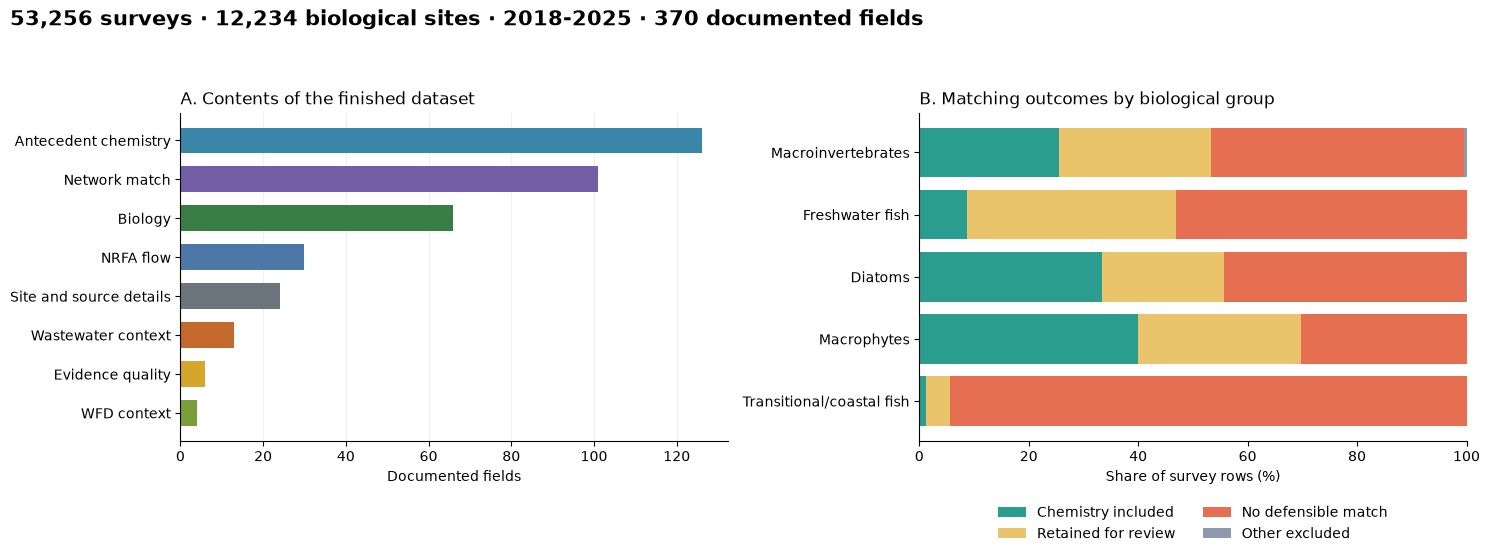

| biological group | survey rows | biology sites | chemistry included (%) |
| --- | --- | --- | --- |
| Macroinvertebrates | 26,015 | 5,953 | 25.5 |
| Freshwater fish | 12,262 | 5,027 | 8.8 |
| Diatoms | 8,038 | 2,530 | 33.3 |
| Macrophytes | 5,290 | 3,183 | 40 |
| Transitional/coastal fish | 1,651 | 343 | 1.2 |

In [2]:
dataset_figure, assemblage_summary = plot_dataset_overview(
    specialist_path,
    completed.dictionary,
    output_directory=output_directory,
)
plt.show()
assemblage_display = assemblage_summary[[
    "survey rows", "biology sites", "chemistry included (%)"
]].round(1)
for count_column in ("survey rows", "biology sites"):
    assemblage_display[count_column] = assemblage_display[count_column].map(
        lambda value: f"{int(value):,}"
    )
display(Markdown(dataframe_markdown(assemblage_display)))


### From biological surveys to integrated evidence

The diagram follows biological survey rows from candidate routes through the matching
checks and into the joined dataset. Review and unmatched rows remain in the saved matching tables.

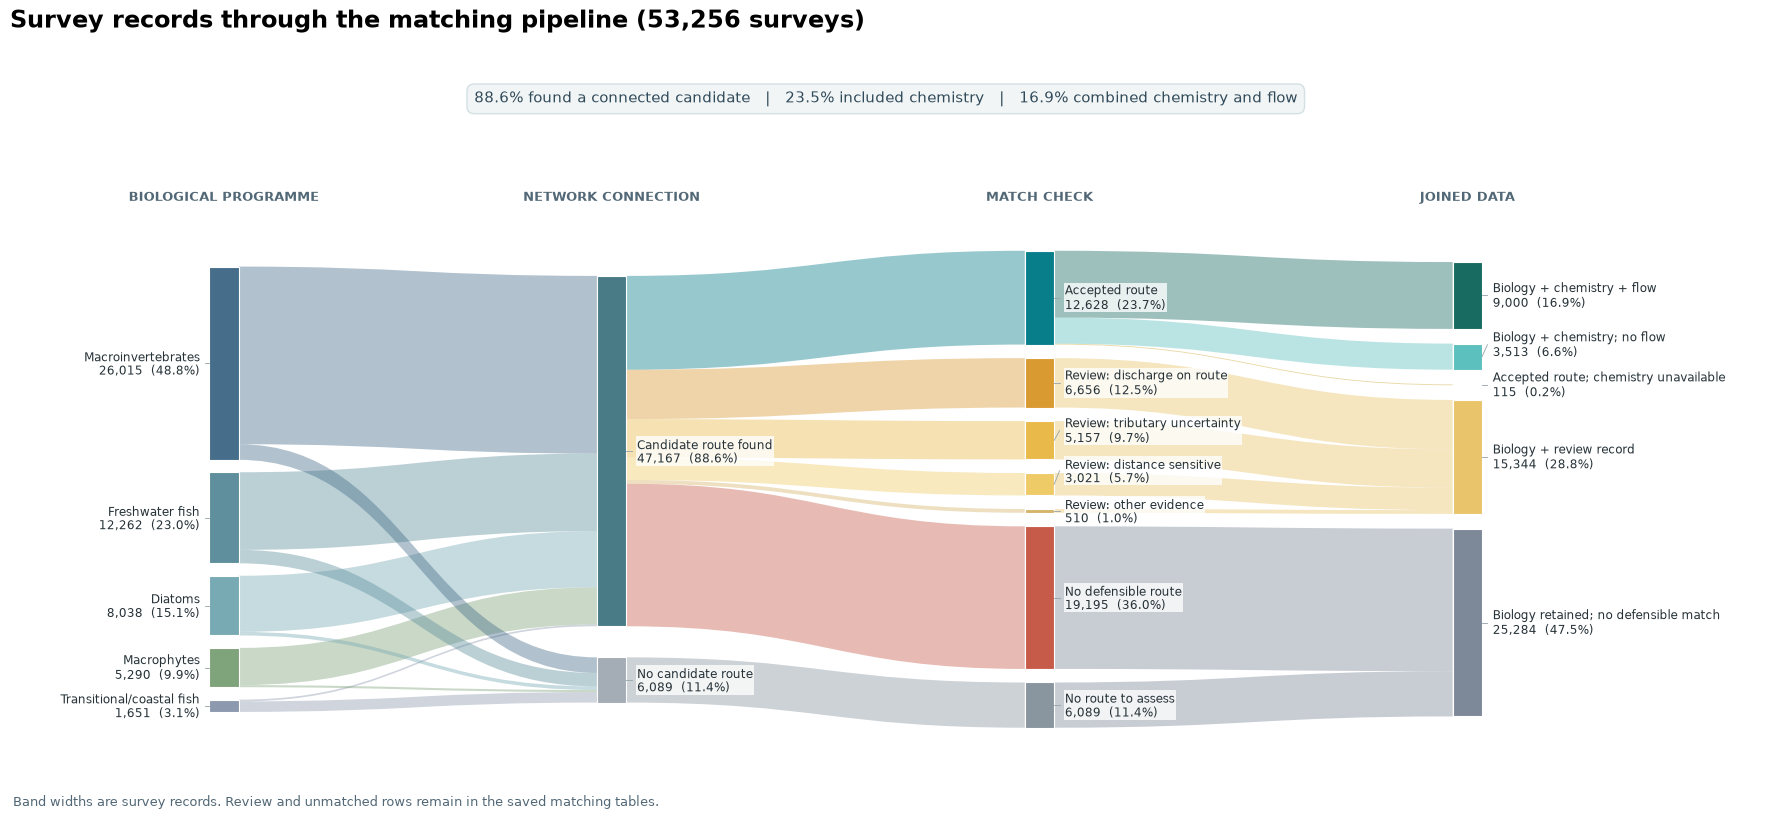

In [3]:
flow_columns = [
    "data_origin", "assemblage", "candidate_count", "match_decision",
    "chemistry_included_in_release", "flow_evidence_available",
]
flow_records = pd.read_parquet(specialist_path, columns=flow_columns)
flow_records = flow_records.loc[flow_records["data_origin"].eq("connected_river_pipeline")]
evidence_figure, evidence_summary = plot_evidence_river(flow_records)
evidence_figure.savefig(
    output_directory / "joined_evidence_sankey.png", dpi=180, bbox_inches="tight"
)
plt.show()


## Where do we have evidence?

The first step is to establish where the available evidence supports analysis.

### National monitoring and matching support

The maps separate the biological monitoring network, repeat-site coverage and included
chemistry. The usable evidence is determined by their overlap, not by the size of any one
source dataset.

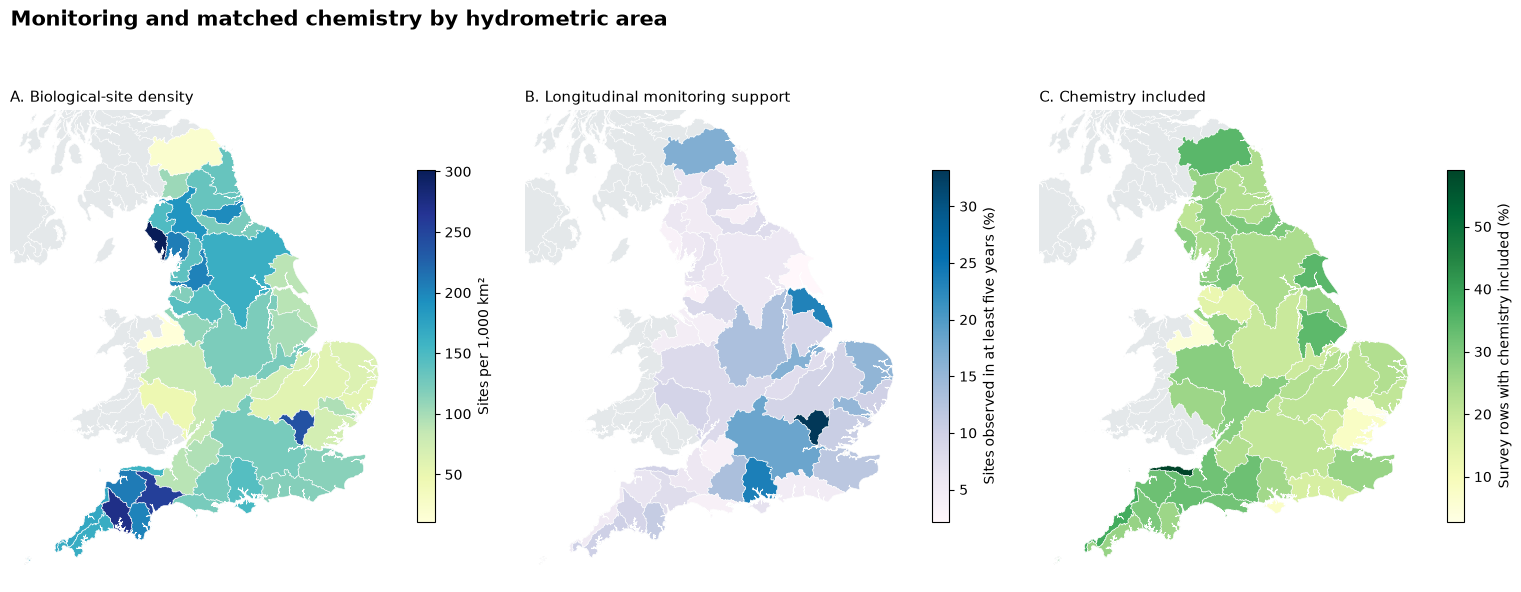

**Lowest included-chemistry coverage in monitored areas:** Stour (Essex and Suffolk) (2.7%); Dee (Cheshire) (5.3%); Isle of Wight (7.5%)

In [4]:
spatial = prepare_spatial_evidence(RELEASE_DIR, specialist_path)
spatial_figure, spatial_summary = plot_spatial_support(
    spatial, output_directory=output_directory
)
plt.show()
lowest_support = spatial_summary.nsmallest(3, "chemistry included rows (%)")
display(Markdown(
    "**Lowest included-chemistry coverage in monitored areas:** " + "; ".join(
        f"{row['hydrometric area']} ({row['chemistry included rows (%)']:.1f}%)"
        for _, row in lowest_support.iterrows()
    )
))


### Three river stories

These examples show three common situations: consistently supported evidence, changing evidence between years and a persistent chemistry gap. They were selected using completeness and match category.


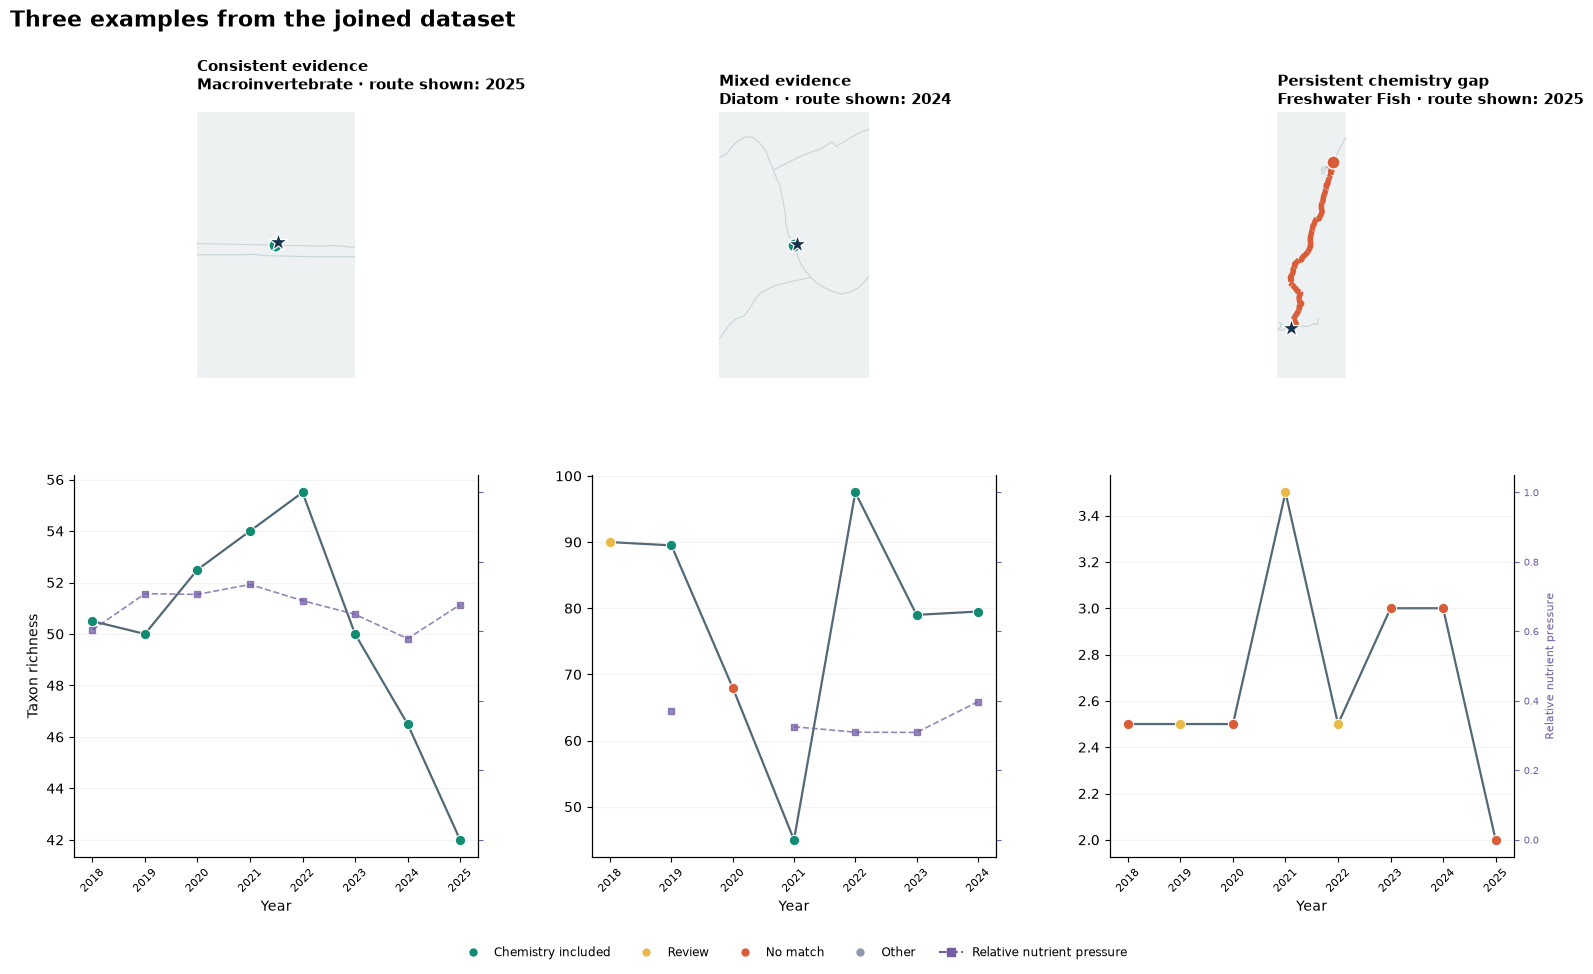

In [5]:
story_figure = plot_river_stories(
    specialist_path, RELEASE_DIR, spatial,
    output_directory=output_directory,
)
plt.show()


## Where are the evidence gaps?

### Integrated evidence by hydrometric area

The fingerprint shows which kinds of analysis are supported in different places. Each
column uses a common 0–100 availability scale; it is not an overall river-health score.
Rows are ordered by included chemistry and repeat-site support.

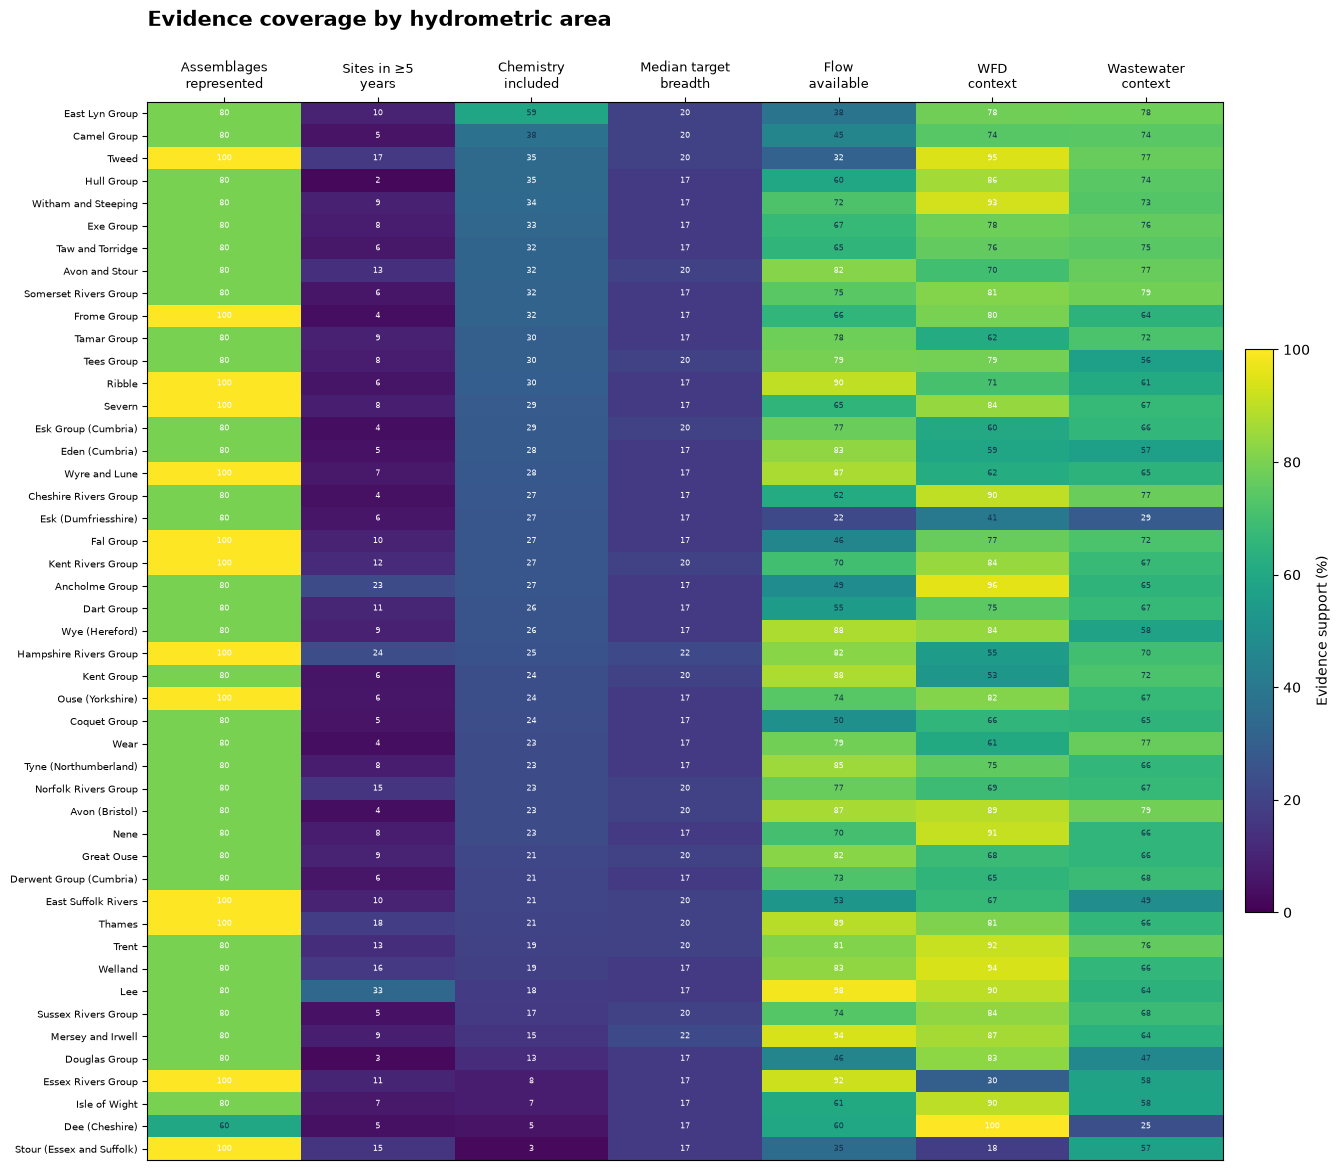

| catchment_name | chemistry included | repeat-site support | flow available | WFD context | wastewater context |
| --- | --- | --- | --- | --- | --- |
| East Lyn Group | 59.1 | 9.6 | 38.4 | 78.3 | 77.8 |
| Camel Group | 37.6 | 5.1 | 45.4 | 73.9 | 74.3 |
| Tweed | 34.7 | 16.7 | 31.5 | 94.9 | 76.7 |
| Hull Group | 34.7 | 2.1 | 60 | 86.2 | 74.2 |
| Witham and Steeping | 34.3 | 9 | 72.1 | 93.1 | 73.3 |
| Exe Group | 33 | 7.8 | 66.9 | 77.8 | 75.8 |

In [6]:
fingerprint_figure, fingerprints = plot_evidence_fingerprint(
    specialist_path, spatial, output_directory=output_directory
)
plt.show()

fingerprint_preview = fingerprints[[
    "catchment_name", "chemistry included", "repeat-site support",
    "flow available", "WFD context", "wastewater context",
]].head(6).round(1)
display(Markdown(dataframe_markdown(fingerprint_preview, include_index=False)))


### Chemistry coverage through time

Not every determinand is measured in every survey window. The heatmap shows that coverage directly, with missing measurements left as missing.


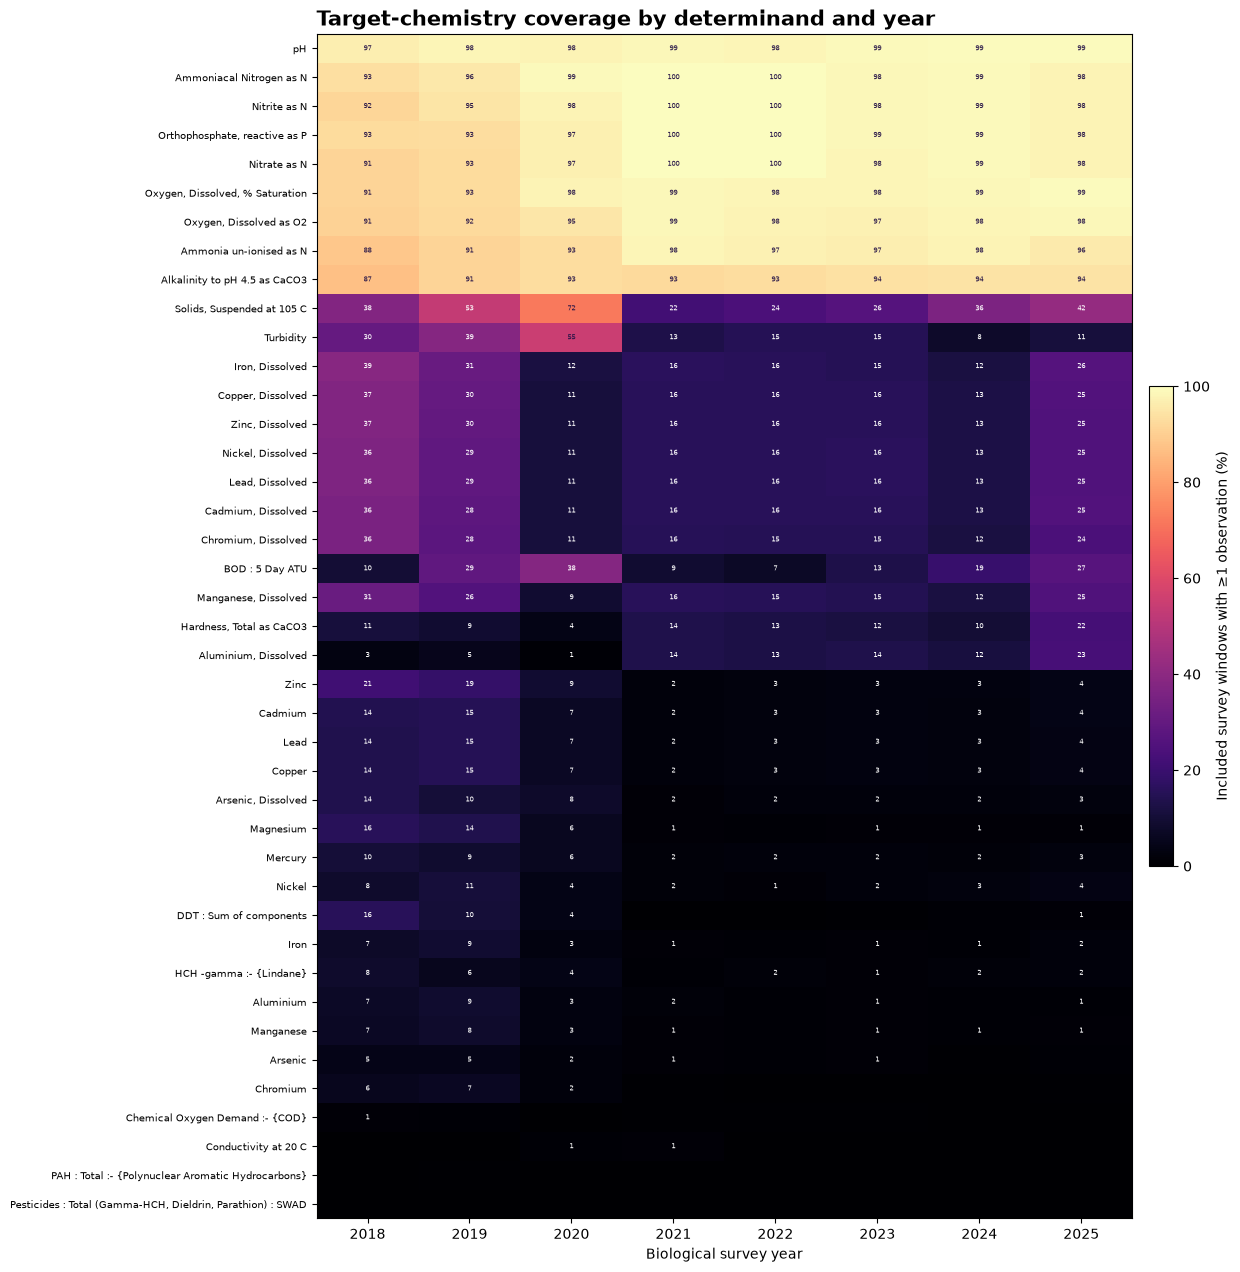

In [7]:
chemistry_figure, chemistry_coverage = plot_chemistry_coverage(
    specialist_path, output_directory=output_directory
)
plt.show()


## Monitoring through time

When the notebook is run, the first map is interactive: zoom, pan and hover over sites to
inspect the 2025 network. Major river links are drawn behind the monitoring sites, so
dense clusters can be separated at local scale. The stored animation gives the annual
overview, and the following figure separates changing survey effort from trends at
repeat sites.

Monitoring fell sharply across programmes in 2020. That interruption coincides with
COVID-19 restrictions and should be treated as a sampling-effort break, not as evidence
of sudden ecological change. The latest year can also be incomplete for individual
programmes, so trend interpretation uses the saved coverage counts alongside the
biological values.



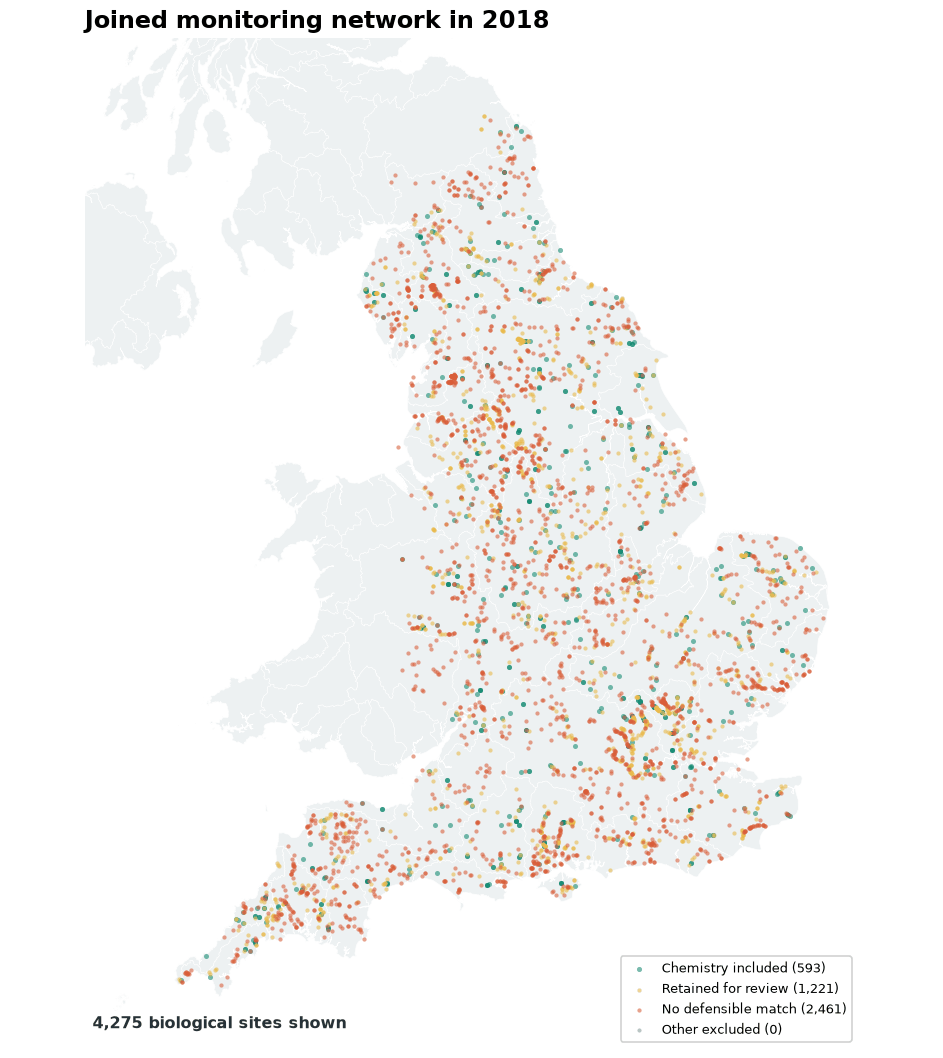

In [8]:
map_year = int(TARGET_YEAR)
interactive_map, interactive_map_path, interactive_sites = (
    build_interactive_monitoring_map(
        specialist_path, RELEASE_DIR, output_directory, year=map_year
    )
)
display(interactive_map)

animation_path = create_monitoring_animation(
    specialist_path, spatial, output_directory
)
animation_data = b64encode(animation_path.read_bytes()).decode("ascii")
display(HTML(
    f'<img src="data:image/gif;base64,{animation_data}" '
    'alt="Animation of monitoring sites and matching decisions from 2018 to 2025" '
    'style="max-width:100%; height:auto;">'
))


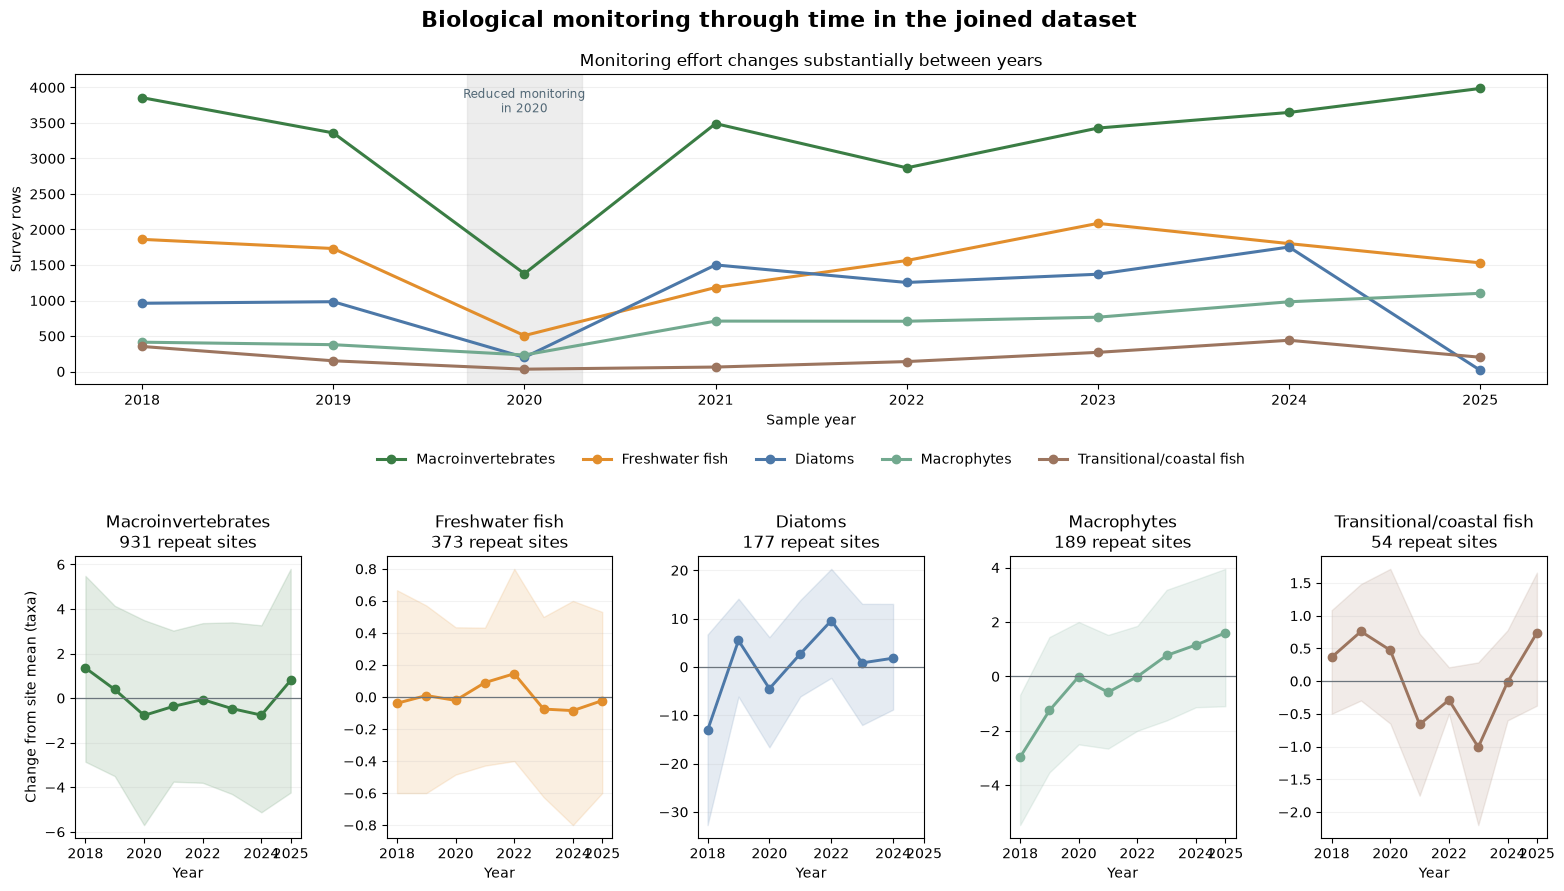

| biological group | sites | median slope | lower quartile | upper quartile |
| --- | --- | --- | --- | --- |
| Macroinvertebrates | 931 | -0.14 | -1.1 | 0.93 |
| Freshwater fish | 373 | -0 | -0.15 | 0.11 |
| Diatoms | 177 | 2 | -1.27 | 6.29 |
| Macrophytes | 189 | 0.6 | -0.08 | 1.2 |
| Transitional/coastal fish | 54 | -0.02 | -0.26 | 0.09 |

In [9]:
biology_figure, trend_summary = plot_biological_monitoring(
    specialist_path, RELEASE_DIR, output_directory=output_directory
)
plt.show()
trend_display = trend_summary.rename(columns={
    "repeated_sites": "sites", "median_slope": "median slope",
    "lower_quartile": "lower quartile",
    "upper_quartile": "upper quartile",
}).round(2)
trend_display.index.name = "biological group"
display(Markdown(dataframe_markdown(trend_display)))


## From monitoring to environmental relationships

### Spatial pattern versus repeat-site change

The two rows answer different questions. The top row compares site medians and shows the
national spatial pattern. The bottom row centres both variables within repeat sites and
looks at changes through time at the same site.

The outcomes are WHPT ASPT for macroinvertebrates, RMNI for macrophytes and taxa richness
for freshwater fish. Points are site-balanced pressure bins and bands are bootstrap
intervals. These are descriptive plots and should not be read as causal effects.

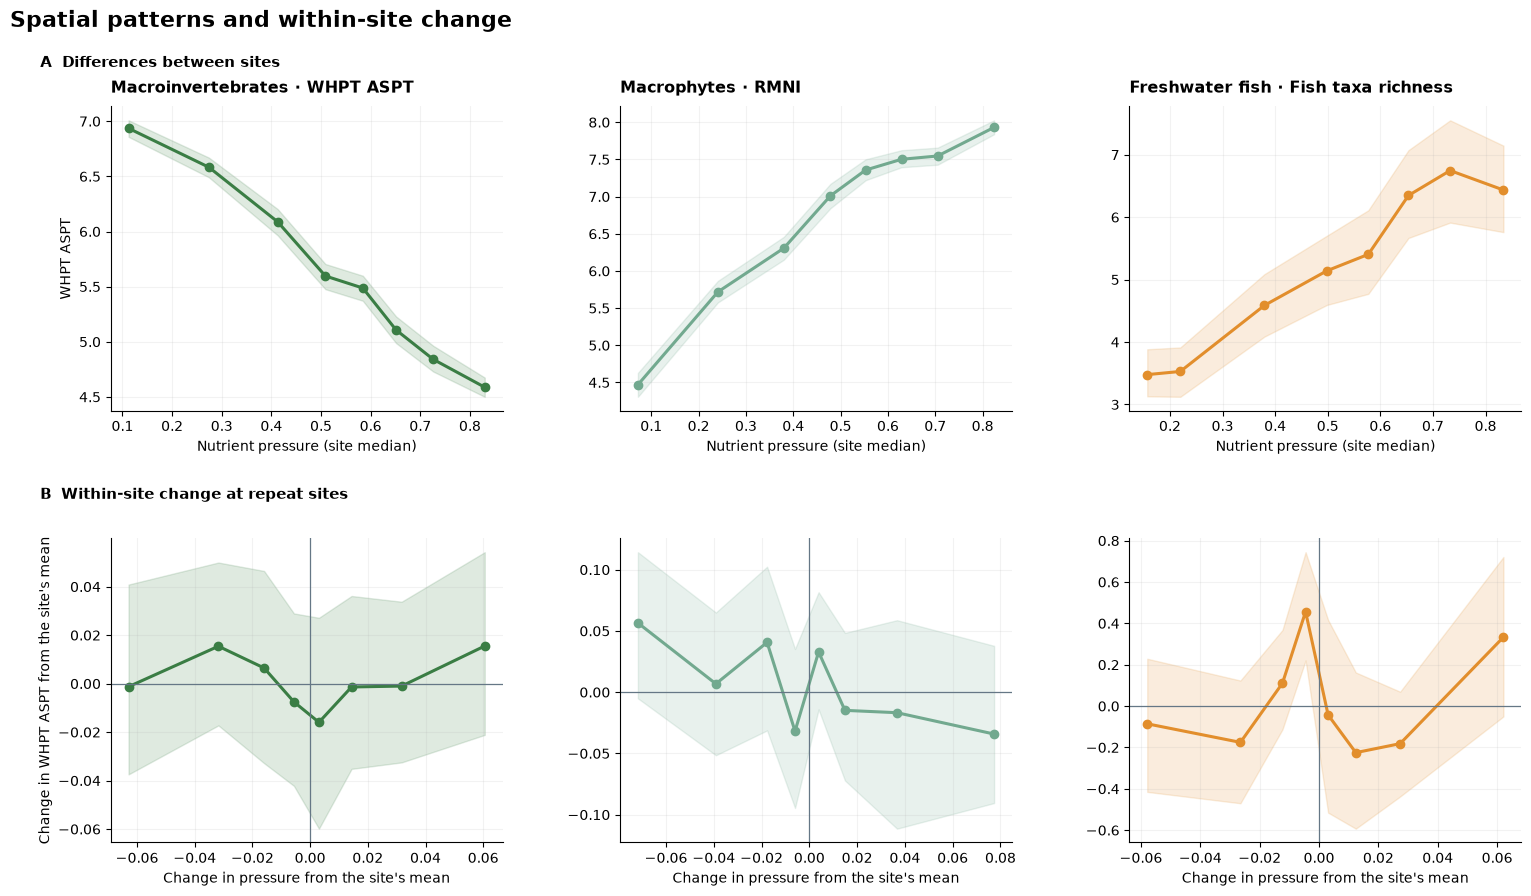

| measure | spatial sites | spatial rho | repeat sites | within-site rho |
| --- | --- | --- | --- | --- |
| WHPT ASPT | 1,982 | -0.71 | 270 | -0.03 |
| RMNI | 1,405 | 0.72 | 101 | -0.13 |
| Fish taxa richness | 563 | 0.41 | 82 | 0.02 |

**Reading the curves.** Macroinvertebrate WHPT ASPT falls and macrophyte RMNI rises across the national nutrient gradient, while fish richness also rises. The repeat-site curves are much flatter. The positive pooled fish relationship probably reflects differences in habitat or river size between sites rather than a beneficial nutrient response.

In [10]:
response_figure, response_summary, response_curves = plot_pressure_response_curves(
    specialist_path, output_directory=output_directory
)
plt.show()

response_display = response_summary.copy()
response_display.insert(0, "measure", response_display.pop("outcome"))
response_display = response_display.drop(columns=["assemblage", "pressure"]).rename(columns={
    "sites in spatial curve": "spatial sites",
    "spatial Spearman correlation": "spatial rho",
    "sites in repeat-site curve": "repeat sites",
    "within-site Spearman correlation": "within-site rho",
})
for count_column in ("spatial sites", "repeat sites"):
    response_display[count_column] = response_display[count_column].map(
        lambda value: f"{int(value):,}"
    )
response_display[["spatial rho", "within-site rho"]] = response_display[[
    "spatial rho", "within-site rho"
]].round(2)
display(Markdown(dataframe_markdown(response_display, include_index=False)))

display(Markdown(
    "**Reading the curves.** Macroinvertebrate WHPT ASPT falls and macrophyte RMNI "
    "rises across the national nutrient gradient, while fish richness also rises. "
    "The repeat-site curves are much flatter. The positive pooled fish relationship "
    "probably reflects differences in habitat or river size between sites rather than "
    "a beneficial nutrient response."
))


<div style="border-left:5px solid #d97706; background:#fff7ed; padding:14px 16px; margin:18px 0;">
<strong>SPATIAL ASSOCIATION ≠ TEMPORAL RESPONSE</strong><br>
Strong differences between sites can reflect river size, habitat, region or monitoring
design. They do not show that changing one pressure will produce the same response through
time at a particular site.
</div>

## What this analysis does not establish

A formal model would also need to account for site, year, season, flow, sampling method,
nonlinear relationships, spatial dependence and censored measurements. A hierarchical
GAM or mixed model could be used for that, with spatially blocked validation and
sensitivity checks using alternative matches.

## Connect the historical and current record

The same integration approach can reconnect a published historical cohort to current
monitoring. ChemPop v2 identifies English river sites sampled through 2018. The open
archive is downloaded from the
[EIDC record](https://doi.org/10.5285/23f194b0-1e21-4f14-be9c-6eabdcc1feb7), then its site,
sample and date identifiers are checked against the ecology archive acquired by this
pipeline.

**Dataset citation:** Bachiller-Jareno, N.; Keller, V.D.J.; Eastman, M.; Edwards, F.K.;
Jürgens, M.D.; Scarlett, P.M.; Rizzo, C.; Antoniou, V.; Dean, H.J.; Sadykova, D.; Qu, Y.;
Johnson, A.C. (2025). *Macroinvertebrate taxonomic abundance, water quality, river flow,
air temperature and environmental site descriptors from English rivers, 1965–2018,
version 2.0*. NERC EDS Environmental Information Data Centre.
DOI: [10.5285/23f194b0-1e21-4f14-be9c-6eabdcc1feb7](https://doi.org/10.5285/23f194b0-1e21-4f14-be9c-6eabdcc1feb7).

### Has macroinvertebrate condition changed, 1965–2025?

WHPT ASPT is taken from the same processed ecology archive throughout the time series, so
the historical and recent values use one measure. The figures separate the number of
sites sampled from the national trajectory and centre values within sites to reduce
changes caused by the composition of the monitoring network.

The period comparison uses the same sites and calendar months in 1990–1999 and 2019–2025.
It describes change in the observed record; it does not assign that change to a cause.

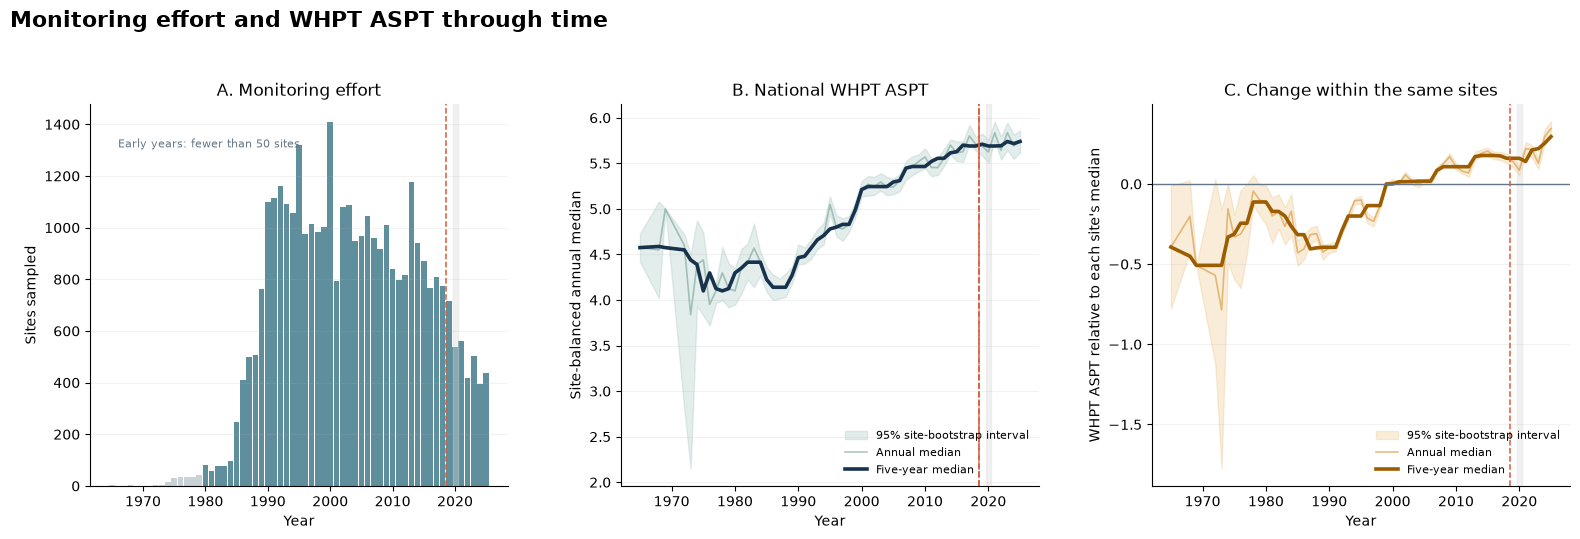

**Historical site matching.** 67,485 of 67,499 deposited samples match exactly (99.98%); 921 of 1,519 original sites have usable later observations.

**Paired long-term comparison**

| historical period | recent period | paired sites | median change | 95% interval | sites higher (%) |
| --- | --- | --- | --- | --- | --- |
| 1990–1999 | 2019–2025 | 848 | 0.52 | +0.47 to +0.56 | 87.9 |

**Long-term pattern.** Coverage is sparse before the mid-1980s, so those early values are shown but not used for the period comparison. The five-year median site-centred value changes from -0.32 in 1985 to +0.29 in 2025. At hydrometric-area level, 33 of 34 areas with at least five paired sites have a positive median change. These are descriptive patterns and do not identify the cause of change.

In [11]:
historical_archive = acquire_historical_archive(
    HISTORICAL_ARCHIVE_INPUT,
    WORKSPACE / "source_cache" / "historical_macroinvertebrates",
)
historical_result = build_historical_continuation(
    RELEASE_DIR, historical_archive, output_directory,
    historical_period=(1990, 1999),
)
display(historical_result.figure)

bridge = historical_result.bridge.iloc[0]
display(Markdown(
    "**Historical site matching.** "
    f"{int(bridge['exact samples found in current EA archive']):,} of "
    f"{int(bridge['deposited samples']):,} deposited samples match exactly "
    f"({bridge['exact match (%)']:.2f}%); "
    f"{int(bridge['sites observed after 2018']):,} of "
    f"{int(bridge['deposited sites']):,} original sites have usable later "
    "observations."
))

paired_display = historical_result.headline.copy()
paired_display["95% interval"] = paired_display.apply(
    lambda row: f"{row['lower 95%']:+.2f} to {row['upper 95%']:+.2f}", axis=1
)
paired_display = paired_display[[
    "historical period", "recent period", "paired sites",
    "median within-site change", "95% interval",
    "sites with higher recent value (%)",
]].rename(columns={
    "median within-site change": "median change",
    "sites with higher recent value (%)": "sites higher (%)",
})
paired_display["paired sites"] = paired_display["paired sites"].map(
    lambda value: f"{int(value):,}"
)
paired_display["median change"] = paired_display["median change"].round(2)
paired_display["sites higher (%)"] = paired_display["sites higher (%)"].round(1)
display(Markdown("**Paired long-term comparison**"))
display(Markdown(dataframe_markdown(paired_display, include_index=False)))

display(Markdown(historical_result.summary_markdown))


### Catchment trajectories

The six panels use the catchments with the most sites in the paired comparison. Lines are shown only when at least five sites contribute to a year.

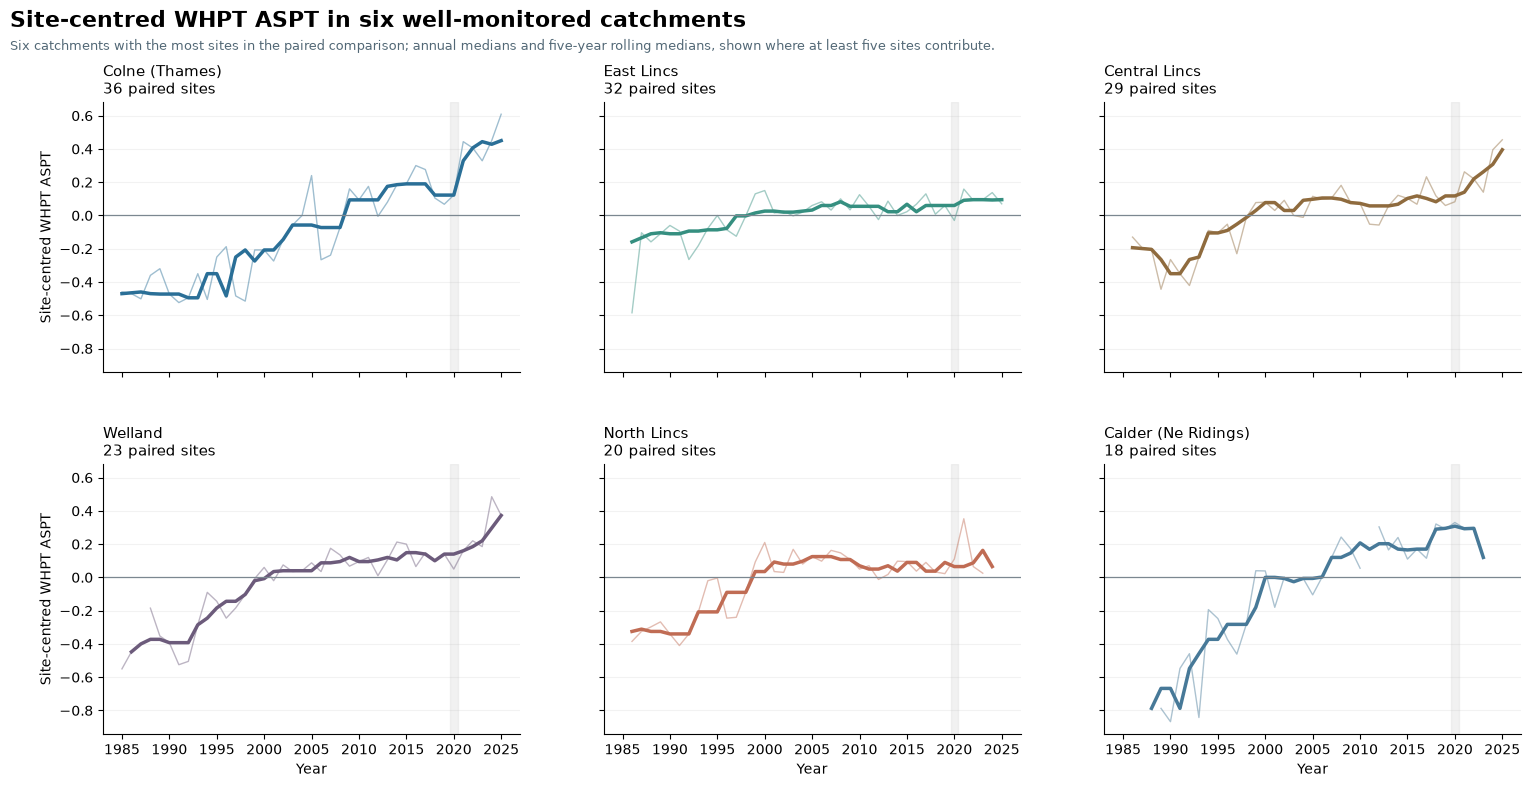

In [12]:
display(historical_result.catchment_figure)


### Change by hydrometric area

The map and ranking summarise the same paired-site changes at a broader spatial scale. Areas with fewer than five paired sites remain grey.

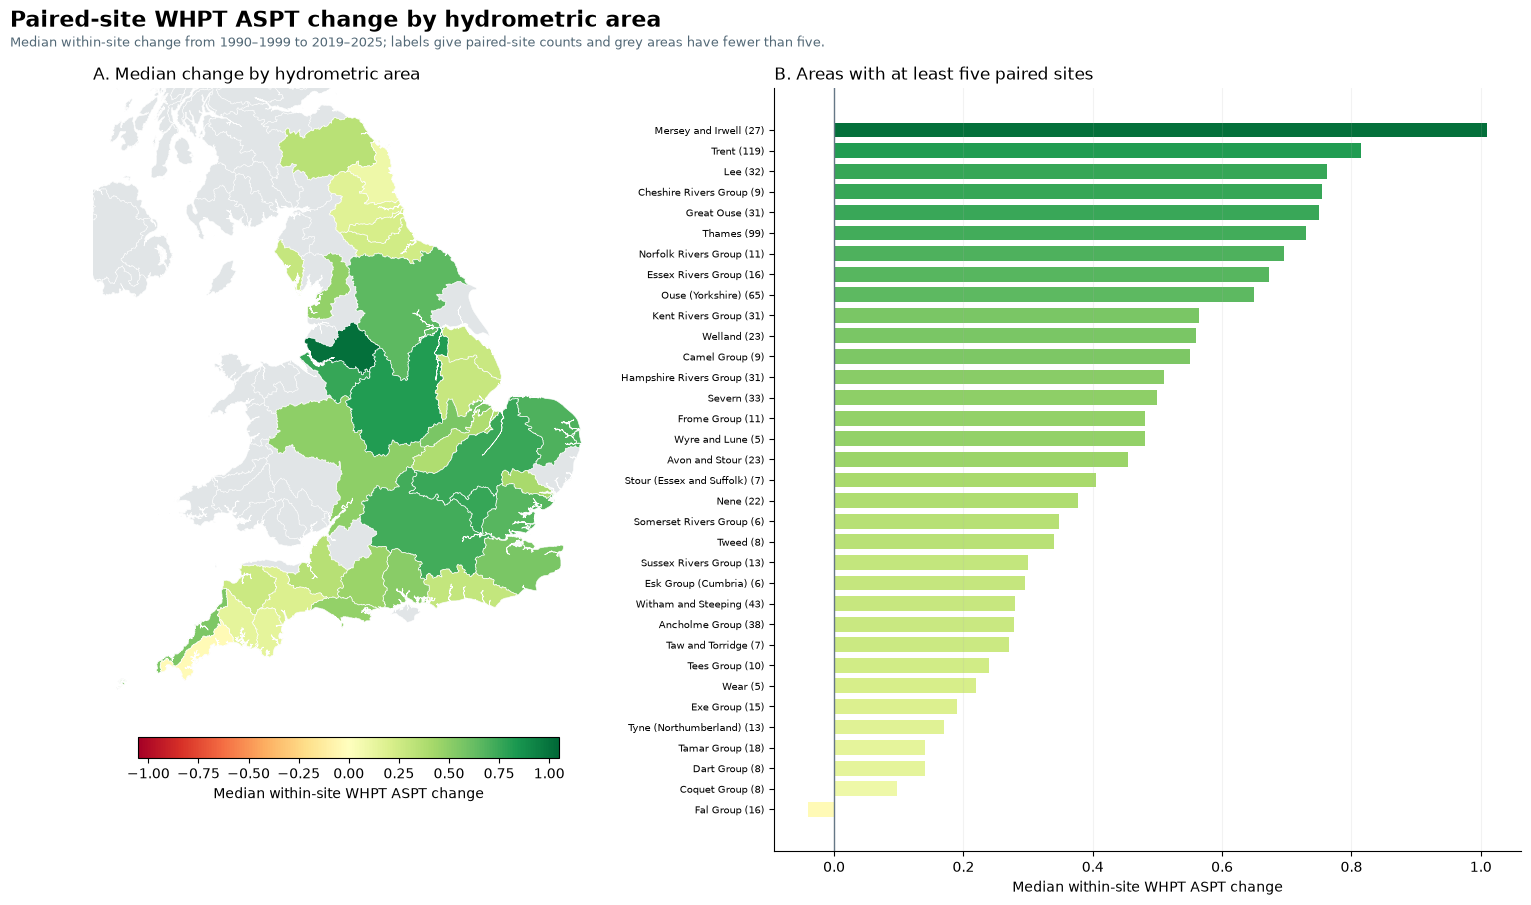

In [13]:
display(historical_result.area_figure)


## What did connecting the data enable?

The connected dataset shows where monitoring evidence overlaps and where gaps still limit
analysis. It separates changes in monitoring effort from biological patterns and supports both
national pressure comparisons and repeat-site change.

Because the integration is reusable, the matched evidence can support further questions without
rebuilding the data connection. [The Connected River (Part 1) - Building](./The_Connected_River_Part_1_Building.ipynb)
documents the method and its quality checks; this notebook demonstrates the analyses it enables.
